# EEG od środka

W ramach tych zajęć zajmiemy się symulowaniem sygnału, tak aby zrozumieć z czego składają się i jak działają prawdziwe pliki danych z zapisów EEG.
Następnie przejrzymy pojedynczy rzeczywisty zapis EEG z publicznej bazy danych

Symulacje ilustrują wybrane zależności; nie są modelem całej fizyki głowy - ta część została celowo uproszczona.
Tworzone przez nas sinusoidy i szum nie odwzorowują pełnego widma EEG, a różne amplitudy czujników nie wynikają z fizycznego modelu przewodzenia przez głowę.

## 0. Przygotowanie

Wybierz kernel środowiska z Pythonem **3.11+** i MNE **1.13.2**.
W razie potrzeby w terminalu tego środowiska wykonaj:

```bash
python -m pip install mne==1.13.2 numpy matplotlib ipykernel
```

Następnie zrestartuj kernel. Uruchamiaj komórki od góry.
Wykresy działają wewnątrz notebooka; Qt nie jest potrzebne.
Części 1–7 korzystają z syntezy i działają offline. W części 8 pobierzesz jeden plik EDF;
po jego zapisaniu także tę część można wykonywać bez internetu.

**Na początek:** zapisz dwie informacje, bez których nie umiesz zinterpretować tablicy EEG.
Co może oznaczać liczba `20`: wolty, mikrowolty, kod bodźca czy numer próbki?


In [1]:
%matplotlib inline
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import mne

mne.set_log_level('WARNING')
plt.rcParams.update({'figure.figsize': (10, 3.2), 'axes.grid': True,
                     'grid.alpha': 0.2, 'font.size': 11})
print('Python:', sys.version.split()[0], '| MNE:', mne.__version__)
print('NumPy:', np.__version__)


Python: 3.14.2 | MNE: 1.13.2
NumPy: 2.5.3


## 1. Skąd bierze się EEG?

### Krótkie podsumowanie

1. Otwarcie kanałów jonowych zmienia przepływ prądu przez błony neuronów.
   Prądy postsynaptyczne w dużych populacjach podobnie zorientowanych neuronów,
   zwłaszcza piramidowych, mogą dawać mierzalny sygnał na skórze głowy.
2. Liczy się **sumowanie w czasie i przestrzeni**: podobny czas aktywności i orientacja
   sprzyjają sumowaniu; przeciwne orientacje mogą powodować znoszenie wkładów.
   Pojedynczy pik jednego neuronu nie jest tym, co zwykle oglądamy w EEG ze skóry głowy.
3. Przewodzenie objętościowe przez tkanki sprawia, że wiele źródeł wnosi wkład do jednej
   elektrody, a jedno źródło może być widoczne na wielu elektrodach. Duży sygnał przy Fz
   nie dowodzi, że generator leży dokładnie pod Fz.
4. Elektroda wraz z kontaktem ze skórą umożliwia pomiar. W zapisie występują też sygnały
   oczu, mięśni, serca i zakłócenia aparatury. „Sygnał EEG” nie oznacza „samo źródło mózgowe”.

## Jak sumują się różne grupy neuronów?

W ramach poniższej symulacji grupę opisujemy czterema wartościami:

```python
[częstotliwość, amplituda, faza, liczba_neuronów]
```

Przykładowo:

```python
[10, 1.0, 0.0, 50]
```

oznacza grupę 50 neuronów, z których każdy wnosi w naszym modelu identyczną sinusoidę o częstotliwości 10 Hz, amplitudzie 1 i fazie początkowej 0.
**W obrębie jednej grupy wszystkie wkłady są identyczne i zsynchronizowane.**

### Czym możemy manipulować?

| Parametr | Znaczenie | Przykład zmiany |
|---|---|---|
| Częstotliwość | Liczba cykli na sekundę, w Hz. | Zmiana z 10 na 20 Hz daje dwa razy więcej oscylacji w tym samym czasie. |
| Amplituda | Maksymalne wychylenie pojedynczego wkładu od zera (w jednostkach umownych). | Zmiana z 1 na 2 podwaja wkład każdego neuronu w grupie. |
| Faza | Położenie w cyklu w chwili rozpoczęcia obserwacji, w radianach. | Dodanie π (`np.pi`) odwraca znak sinusoidy. |
| Liczba neuronów | Liczba identycznych wkładów sumowanych wewnątrz grupy. | Zmiana z 50 na 100 podwaja wkład grupy przy pozostałych parametrach bez zmian. |

Podawaj nieujemne amplitudy i dodatnie, całkowite liczebności. Częstotliwości powinny być dodatnie i mniejsze niż połowa częstotliwości próbkowania `sfreq`.

### Co dokładnie obliczamy?

Pojedynczą grupę neuronów opisuje równanie:

$$
x(t) = A\sin(2\pi f t + \varphi)
$$

gdzie:

- $A$ — amplituda,
- $f$ — częstotliwość w Hz,
- $t$ — czas w sekundach,
- $\varphi$ — faza początkowa w radianach.

Ponieważ grupa zawiera $N$ identycznych, "zsynchronizowanych neuronów", jej sygnał wynosi:

$$
x_{\mathrm{grupy}}(t) = N A\sin(2\pi f t + \varphi)
$$

Następnie dodajemy sygnały wszystkich grup **osobno w każdym momencie czasu**:

$$
S(t) = \sum_i x_i(t)
$$

W jednym momencie wartości mogą się wzmacniać, a w innym częściowo lub całkowicie znosić.

### Co oznacza przesunięcie fazowe?

Faza jest podawana w **radianach**, nie w sekundach:

- `0` — fala zaczyna od zera i rośnie;
- `np.pi / 2` — fala zaczyna od swojego dodatniego maksimum;
- `np.pi` — fala ma przeciwny znak niż fala o fazie 0;
- `2 * np.pi` — pełny obrót cyklu, czyli taki sam przebieg jak przy fazie 0.

Dla sinusoidy zachodzi:

$$
\sin(\theta + \pi) = -\sin(\theta)
$$

Dodatnia faza we wzorze z plusem oznacza wyprzedzenie. Jeśli chcemy opisać opóźnienie o $\tau$ sekund, możemy użyć:

$$
\varphi = -2\pi f\tau
$$

To samo przesunięcie fazowe odpowiada różnym przesunięciom w sekundach przy różnych częstotliwościach.

### Jak czytać wykres?

- **Każdy kolor** przedstawia łączny wkład jednej grupy, już po przemnożeniu przez jej liczebność.
- **Czarna linia** przedstawia sumę wszystkich grup.
- Jeśli dwie grupy mają identyczny przebieg, ich linie nakładają się.

Parametr `pokaz_skladowe=True` włącza kolorowe linie. Ustawienie `False` pozostawia tylko sumę.

Parametr `alpha` reguluje krycie kolorowych linii: **Alpha zmienia tylko wygląd wykresu. Nie zmienia udziału grupy w sumie.**

### Czas, próbkowanie i skala

`czas` określa długość symulacji w sekundach. `sfreq` określa liczbę próbek na sekundę.

Przy domyślnych ustawieniach `czas=1` i `sfreq=500` otrzymujemy 500 próbek: od 0 do 0,998 s. Zwiększenie `sfreq` zagęszcza punkty, ale nie zmienia zadanych częstotliwości fal.

Domyślna skala osi pionowej wynika z sumy amplitud grup:

$$
\sum_i N_i A_i
$$

Jest to górna granica możliwej wartości bezwzględnej sumy, a nie obietnica, że sygnał ją osiągnie.

Przy porównywaniu różnych tabel ustaw ten sam `limit_y`, np.:

```python
suma_populacji(grupy, limit_y=100)
```

Oś będzie wtedy obejmować zakres od −100 do +100. Dzięki temu zmiana skali nie zamaskuje zmiany wielkości sygnału. Wybierz zakres dostatecznie duży, aby nie ucinać wykresu.

In [34]:
import numpy as np
import matplotlib.pyplot as plt


def suma_populacji(
    grupy,
    pokaz_skladowe=True,
    alpha=0.4,
    czas=1.0,
    sfreq=500,
    limit_y=None,
):
    # Jeden wiersz: [częstotliwość, amplituda, faza, liczba neuronów]
    grupy = np.asarray(grupy, dtype=float)
    t = np.arange(int(czas * sfreq)) / sfreq

    # Każda grupa zawiera identyczne, zsynchronizowane wkłady.
    skladowe = np.array([
        N * A * np.sin(2 * np.pi * f * t + faza)
        for f, A, faza, N in grupy
    ])

    suma = skladowe.sum(axis=0)

    fig, ax = plt.subplots(figsize=(11, 4))
    kolory = plt.cm.hsv(np.linspace(0, 1, len(grupy), endpoint=False))

    if pokaz_skladowe:
        for i, (sygnal, kolor) in enumerate(zip(skladowe, kolory)):
            ax.plot(t, sygnal, color=kolor, alpha=alpha, linewidth=1)

            # Czytelny kolor w legendzie, niezależny od przezroczystości fali.
            ax.plot([], [], color=kolor, label=f"Grupa {i + 1}")

    ax.plot(t, suma, color="black", linewidth=2, label="Suma")

    if limit_y is None:
        limit_y = max(1.0, 1.05 * np.sum(grupy[:, 1] * grupy[:, 3]))

    ax.set(
        xlabel="Czas [s]",
        ylabel="Wartość [j.u.]",
        ylim=(-limit_y, limit_y),
    )
    ax.grid(alpha=0.2)
    ax.legend()
    plt.show()

    return t, skladowe, suma

Liniowe skalowanie przez liczbę neuronów jest tutaj konsekwencją silnego założenia: wszystkie wkłady w grupie są identyczne i zgodne.

**W rzeczywistym EEG znaczenie mają również geometria źródeł, ich orientacja, przewodzenie przez tkanki i referencja.** Na podstawie tego modelu nie można przeliczać amplitudy EEG na rzeczywistą liczbę aktywnych neuronów.

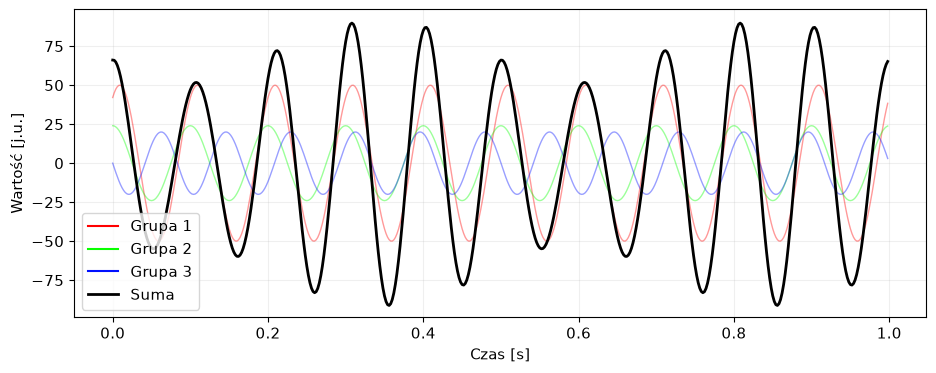

In [ ]:
grupy = [
    # Hz, amplituda, faza [rad], liczba neuronów
    [10, 1.0, 1.0,       50],
    [10, 0.8, np.pi / 2, 30],
    [12, 1.0, np.pi,     20],
]

t, skladowe, suma = suma_populacji(grupy)

### Eksperyment 1

Zacznij od 1 sygnału.

Nastepnie uruchom funkcję dla dwóch dwóch identycznych grup:

Przed uruchomieniem przewidź wielkość sumy.

In [ ]:
### Miejsce na rozwiązanie

### Eksperyment 2
Następnie zmień **wyłącznie fazę drugiej grupy** z `0.0` na `np.pi`.

- Co stało się z sumą?
- Czy poszczególne grupy przestały wnosić sygnał?
- Czy mała suma musi oznaczać małe wkłady?

In [38]:
### Miejsce na rozwiązanie

### Eksperyment 3
Zachowaj przeciwne fazy, ale zmień liczebność drugiej grupy z 50 na 30.

- Czy sygnały nadal znoszą się całkowicie?
- Jaka część sygnału pozostaje?
- Czy taki sam wynik uzyskasz przez zmianę amplitudy zamiast liczebności?

In [ ]:
### Miejsce na rozwiązanie

^ W tym modelu amplituda i liczebność występują jako iloczyn $N A$. Podwojenie amplitudy i podwojenie liczebności daje więc ten sam efekt. **Z samego wyniku nie rozróżnimy tych dwóch przyczyn.**

### Eksperyment 4

Przywróć jednakowe amplitudy i liczebności. Ustaw częstotliwości na 10 i 12 Hz.

- Czy grupy mogą przez cały czas pozostawać zgodne albo przeciwne?
- Czy dodanie π do fazy jednej grupy wystarczy, aby suma zawsze była zerowa?
- Czy suma nadal wygląda jak pojedyncza sinusoida?

In [ ]:
### Miejsce na rozwiązanie

### Eksperyment 5 - plac zabaw
Przygotuj dowolną symulację (z conajmniej 5 różnych składowych) i postaraj się opisać jej właściwości

In [ ]:
### Miejsce na rozwiązanie

### Co wynika z tego dla rozumienia EEG?

Wielkość sygnału zależy nie tylko od wielkości poszczególnych składowych, ale też od sposobu ich sumowania.

**Mały sygnał nie dowodzi braku aktywności — może wynikać ze znoszenia się sygnału z różnych.**

## 2. Referencja

### Koncept

Kanał EEG opisuje **różnicę potencjałów**. W uproszczeniu: `kanał A = V(A) − V(R)`.
Referencja R także może zawierać aktywność fizjologiczną, zakłócenia itd.
Nie ma jednej uniwersalnej „elektrycznie czystej" referencji.

W typowym wzmacniaczu różnicowym wspólna składowa jest tłumiona. Rola elektrody ground
wiąże się z pracą układu pomiarowego; nie jest ona prostym „zerem aktywności mózgowej”.

### Przewidź, a potem sprawdź
1) Czy zmiana referencji może zmienić kształt sygnału?
2) Co stanie się z różnicą Fz − Pz, jeśli od obu odejmiemy tę samą referencję?

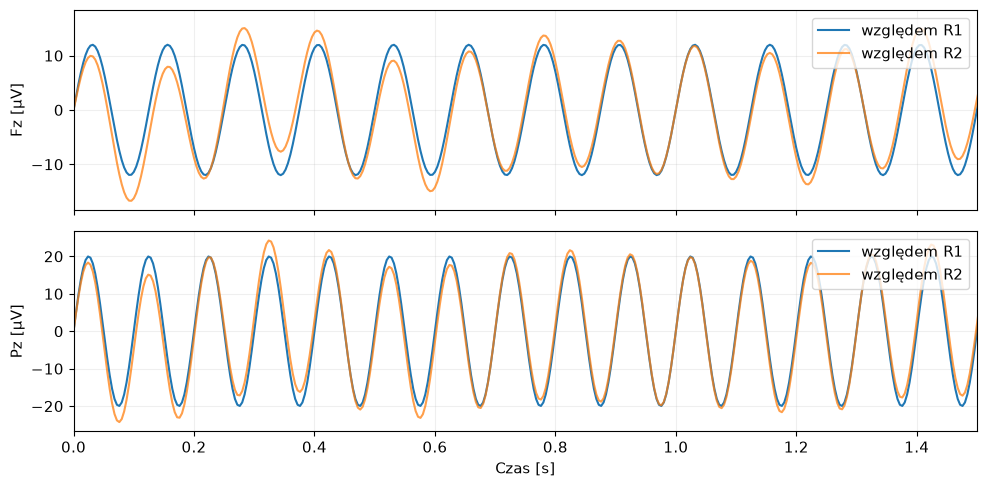

In [48]:
t_ref = np.arange(1000) / 250
# Umowne potencjały względem wspólnego zera modelu, w mikrowoltach.
V_Fz = 12*np.sin(2*np.pi*8*t_ref)
V_Pz = 20*np.sin(2*np.pi*10*t_ref)
V_R1 = np.zeros_like(t_ref)
V_R2 = 3*np.sin(2*np.pi*2*t_ref) + 2*np.sin(np.pi*5*t_ref)

fig, axes = plt.subplots(2, 1, sharex=True, figsize=(10, 5))
for ax, nazwa, v in zip(axes, ['Fz', 'Pz'], [V_Fz, V_Pz]):
    ax.plot(t_ref, v-V_R1, label='względem R1')
    ax.plot(t_ref, v-V_R2, label='względem R2', alpha=.75)
    ax.set(ylabel=f'{nazwa} [µV]', xlim=(0, 1.5))
    ax.legend(loc='upper right')
axes[-1].set_xlabel('Czas [s]')
plt.tight_layout(); plt.show()

In [50]:
print('Czy różnica Fz−Pz nie zależy od wspólnej referencji?')
np.allclose((V_Fz-V_R1)-(V_Pz-V_R1), (V_Fz-V_R2)-(V_Pz-V_R2))

Czy różnica Fz−Pz nie zależy od wspólnej referencji?


True

### Twój eksperyment

**TODO:** skonstruuj referencję `(Fz + Pz) / 2`. Przewidź, jak będą wyglądały dwa
kanały po jej odjęciu. Sprawdź sumę kanałów i ich różnicę. Czy dwa przeciwne przebiegi
muszą oznaczać dwa przeciwstawne procesy mózgowe?

**Zastanów się:** zapisz algebraicznie odejmowanie tego samego R od A i B.


In [51]:
# TODO: zastąp poniższą referencję średnią z V_Fz i V_Pz.

V_Fz = 12*np.sin(2*np.pi*8*t_ref)
V_Pz = 20*np.sin(2*np.pi*10*t_ref)

referencja = # Stwórz swoj kanał referencyjny - na łatwiznę: V_R1.copy()

moje_Fz = # Co tu musi się wydarzyć?
moje_Pz = # Co tu musi się wydarzyć?


plt.plot(t_ref, moje_Fz, label='Fz'); plt.plot(t_ref, moje_Pz, label='Pz')
plt.xlim(0, 1); plt.xlabel('Czas [s]'); plt.ylabel('µV'); plt.legend(); plt.show()

print('Różnica zachowana?', np.allclose(moje_Fz-moje_Pz, V_Fz-V_Pz))


SyntaxError: invalid syntax (986198614.py, line 6)

## 3. Od próbkowania do `Raw` i `Info`

### Koncept

**Źródła → przewodzące tkanki → kontakt elektroda–skóra → wzmacniacz różnicowy
→ filtr antyaliasingowy przed cyfryzacją → ADC → próbki EEG, które my widzimy w pliku wynikowym.**


ADC dyskretyzuje czas i amplitudę. Częstotliwość próbkowania mówi, ile próbek na sekundę
przypada **na każdy kanał**.

Sygnał powyżej pasma dopuszczalnego dla próbkowania może udawać niższą częstotliwość (aliasing)

`Raw` opisuje ciągły zapis (także już wstępnie przetworzony; nazwa nie gwarantuje „nietknięcia” przez kogoś wcześniej).

`RawArray` jest sposobem zbudowania go z tablicy **kanały × próbki**.
Dla EEG/EOG/ECG `RawArray` oczekuje **woltów**: 20 µV = 20 × 10⁻⁶ V.

`Info` opisuje metadane m.in. `sfreq`, nazwy i typy kanałów, zaznaczone złe kanały i informacje o pomiarze.
Nie zawiera całej historii eksperymentu.

`Annotations` są dostępne osobno przez `raw.annotations`.

Kanał `stim` zawiera kody, nie mikrovolty. Czytniki plików MNE zwykle wykonują konwersję
jednostek według nagłówka; nie skaluj ponownie importowanego EEG „na wszelki wypadek”.


### Przewidź, a potem sprawdź
8 kanałów, 20 s, 250 Hz.

1) Jaki będzie kształt tablicy?
2) Jaki czas ma ostatnia próbka?

### Chwila na prawdziwy sygnał

In [107]:
# Pobieranie
from urllib.request import urlopen

URL_EDF = 'https://physionet.org/files/eegmmidb/1.0.0/S001/S001R03.edf'
plik_edf = Path('dane') / 'S001R03.edf'
POBIERZ_JESLI_BRAK = True

print('Szukam pliku:', plik_edf.resolve())
if not plik_edf.exists() and POBIERZ_JESLI_BRAK:
    plik_edf.parent.mkdir(parents=True, exist_ok=True)
    # Zapis dopiero po odebraniu całego pliku; przerwane pobieranie nie tworzy EDF.
    with urlopen(URL_EDF, timeout=60) as odpowiedz:
        zawartosc = odpowiedz.read()
    if zawartosc[:8].strip() != b'0':
        raise ValueError('Pobrana zawartość nie wygląda jak EDF. Użyj linku w przeglądarce.')
    plik_edf.write_bytes(zawartosc)

if not plik_edf.is_file():
    raise FileNotFoundError(
        'Pobierz S001R03.edf do folderu dane lub ustaw POBIERZ_JESLI_BRAK=True, '
        'a następnie ponownie uruchom tę komórkę.')
print('Plik gotowy, rozmiar:', round(plik_edf.stat().st_size/1e6, 2), 'MB')


Szukam pliku: /Users/bejson/University/Dydaktyka/ADNeuroPy/dane/S001R03.edf
Plik gotowy, rozmiar: 2.6 MB


In [108]:
x = mne.io.read_raw_edf(plik_edf, preload=True, verbose=False)
x

<RawEDF | S001R03.edf, 64 x 20000 (125.0 s), ~9.8 MiB, data loaded>

### Wracamy do symulacji na dluzej

In [ ]:
def zbuduj_raw(sfreq=250.0, czas=20.0, seed=67):
    rng = np.random.default_rng(seed)
    t = np.arange(int(round(sfreq*czas))) / sfreq
    nazwy = ['Fz', 'Cz', 'Pz', 'Oz', 'C3', 'C4', 'EOG', 'STI 014']
    typy = ['eeg']*6 + ['eog', 'stim']
    alfa = np.sin(2*np.pi*10*t)
    theta = np.sin(2*np.pi*5*t + .3)
    mrugniecie = np.exp(-0.5*((t-7.5)/.16)**2)
    eeg_uv = (np.array([6, 8, 16, 22, 10, 10])[:, None]*alfa
              + np.array([8, 6, 3, 2, 5, 5])[:, None]*theta
              + rng.normal(0, 2, (6, len(t))))
    eeg_uv += np.array([70, 30, 10, 4, 18, 18])[:, None]*mrugniecie
    eog_uv = 130*mrugniecie + rng.normal(0, 3, len(t))
    stim = np.zeros(len(t))
    for sekunda, kod in [(3, 1), (10, 2), (15, 1)]:
        start = int(round(sekunda*sfreq))
        if start < len(t):
            stim[start:start+max(2, int(.02*sfreq))] = kod
    dane = np.vstack([eeg_uv*1e-6, eog_uv[None, :]*1e-6, stim[None, :]])
    info = mne.create_info(nazwy, sfreq, typy)
    return mne.io.RawArray(dane, info, verbose=False)

In [103]:
raw = zbuduj_raw()

print(raw)
print('Kształt:', raw.get_data().shape)
print('sfreq:', raw.info['sfreq'], 'Hz')
print('Czas ostatniej próbki:', raw.times[-1], 's')
print('Liczba próbek / sfreq:', raw.n_times/raw.info['sfreq'], 's')
print('Nazwy:', raw.ch_names)
print('Złe kanały:', raw.info['bads'])
print('Pomiar — data:', raw.info['meas_date'])
print('Oz, pierwsze 5 wartości w V:', raw.get_data(picks=['Oz'])[0, :5])

<RawArray | 8 x 5000 (20.0 s), ~323 KiB, data loaded>
Kształt: (8, 5000)
sfreq: 250.0 Hz
Czas ostatniej próbki: 19.996 s
Liczba próbek / sfreq: 20.0 s
Nazwy: ['Fz', 'Cz', 'Pz', 'Oz', 'C3', 'C4', 'EOG', 'STI 014']
Złe kanały: []
Pomiar — data: None
Oz, pierwsze 5 wartości w V: [3.01840717e-06 7.77105582e-06 1.19645307e-05 1.75790155e-05
 2.00496685e-05]


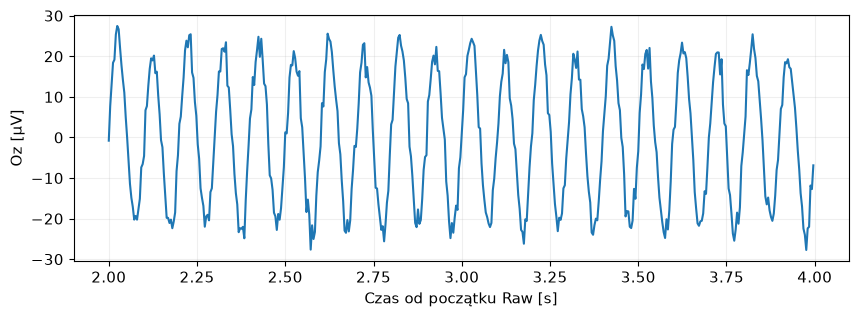

In [104]:
# Wycinamy [2, 4) s przez indeksy, nie przez modyfikację raw.
a, b = raw.time_as_index([2, 4])
fragment = raw.get_data(picks=['Oz'], start=a, stop=b, units='uV')[0]

plt.plot(raw.times[a:b], fragment)
plt.xlabel('Czas od początku Raw [s]'); plt.ylabel('Oz [µV]'); plt.show()


### Eksperyment 1
Przewidź kształt i ostatni czas po zmianie `sfreq` z 250 na 500 Hz.
Wygeneruj nowy zapis o tym samym czasie trwania.
To **nowa symulacja pomiaru**, nie resampling.

In [105]:
### Miejsce na rozwiązanie, użyj funkcji zbuduj_raw()

### Eksperyment 2
Pobierz 1 sekundę jednego wybranego kanału EEG, wypisz kształt i największą
wartość bezwzględną w µV. 
Ile wymiarów będzie miała tablica? Dlaczego?

In [106]:
### Miejsce na rozwiązanie, na początku użyj funkcji zbuduj_raw(), wybierz kanał EEG i granice dokładnie jednej sekundy na stworzonym sygnale "raw"
# i, j = raw.time_as_index([start, stop])
# fragment = raw.get_data(picks=[moj_kanal], start=i, stop=j, units='uV')
# Przyda się: print('Kształt:', fragment.shape, '| max |µV|:', np.max(np.abs(fragment)))

## 4. Rodzaje kanałów

- EEG: różnice potencjałów używane do badania aktywności mózgowej.
- EOG: pomiar związany z oczami; pomaga rozpoznawać mrugnięcia i ruchy oczu.
- ECG: pomiar aktywności elektrycznej serca.
- `stim`: kody zdarzeń.

Typ to metadana o roli kanału, nie automatyczny wynik klasyfikacji jego kształtu.
Nasza symulacja zawiera EEG, EOG i stim

### Sprawdź
- Co zmienia zmiana nazwy kanału?
`raw.rename_channels({"stara_nazwa": "nowa_nazwa"})`
- Co zmienia typ kanału?
`raw.set_channel_types({"nazwa": "typ"})`

In [63]:
# Jak sprawdzić aktyalne nazwy i typy kanałów?
list(zip(raw.ch_names, raw.get_channel_types()))

[('Fz', 'eeg'),
 ('Cz', 'eeg'),
 ('Pz', 'eeg'),
 ('Oz', 'eeg'),
 ('C3', 'eeg'),
 ('C4', 'eeg'),
 ('EOG', 'eog'),
 ('STI 014', 'stim')]

In [ ]:
# Miejsce na zadanie

Lista kanałów wraz z ich typami: [('Fz', 'eeg'), ('Cz', 'eeg'), ('Pz', 'eeg'), ('Oz', 'eeg'), ('C3', 'eeg'), ('C4', 'eeg'), ('EOG', 'eog'), ('STI 014', 'stim')]
Tylko EEG: ['Fz', 'Cz', 'Pz', 'Oz', 'C3', 'C4']


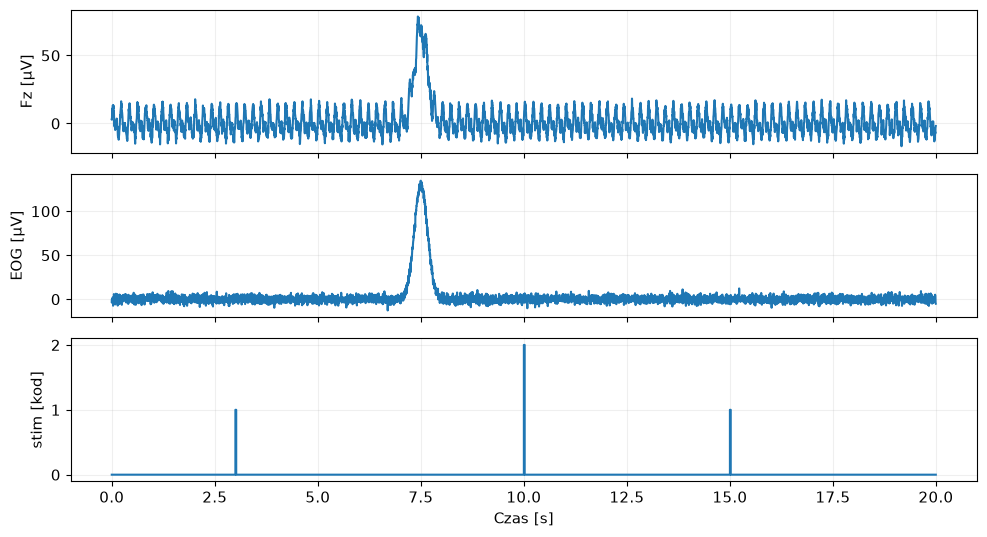

In [58]:
print(f"Lista kanałów wraz z ich typami: {list(zip(raw.ch_names, raw.get_channel_types()))}")
print('Tylko EEG:', raw.copy().pick('eeg').ch_names)


fig, axes = plt.subplots(3, 1, sharex=True, figsize=(10, 5.5))
for ax, kanal in zip(axes[:2], ['Fz', 'EOG']):
    ax.plot(raw.times, raw.get_data(picks=[kanal], units='uV')[0])
    ax.set_ylabel(f'{kanal} [µV]')
axes[2].step(raw.times, raw.get_data(picks=['STI 014'])[0], where='post')
axes[2].set(ylabel='stim [kod]', xlabel='Czas [s]')
plt.tight_layout(); plt.show()


### Nazwa to jeszcze nie pozycja

- `montage` w MNE przypisuje kanałom pozycje elektrod i może zawierać punkty odniesienia anatomicznego. Nazwa kanału jest kluczem do dopasowania, nie współrzędnymi.
Pozycje są wyrażone w metrach wraz z układem współrzędnych. Montaż to dostępny "standardowy wzorzec", a nie indywidualny pomiar głowy uczestnika.


`mne.channels.get_builtin_montages()` - sprawdź do czego dostęp daje MNE

- `colin27_1020` to standardowy czepek, starsza nazwa `standard_1020` została już wycofywana (bez sensu).

In [66]:
mne.channels.get_builtin_montages()

['fsaverage_1005',
 'fsaverage_1010',
 'fsaverage_1020',
 'colin27_1005',
 'colin27_1020',
 'colin27_alphabetic',
 'colin27_postfixed',
 'colin27_prefixed',
 'colin27_primed',
 'biosemi16',
 'biosemi32',
 'biosemi64',
 'biosemi128',
 'biosemi160',
 'biosemi256',
 'easycap-M1',
 'easycap-M10',
 'easycap-M43',
 'EGI_256',
 'GSN-HydroCel-32',
 'GSN-HydroCel-64_1.0',
 'GSN-HydroCel-65_1.0',
 'GSN-HydroCel-128',
 'GSN-HydroCel-129',
 'GSN-HydroCel-256',
 'GSN-HydroCel-257',
 'mgh60',
 'mgh70',
 'artinis-octamon',
 'artinis-brite23',
 'brainproducts-RNP-BA-128',
 'spherical_1005',
 'spherical_1010',
 'spherical_1020']

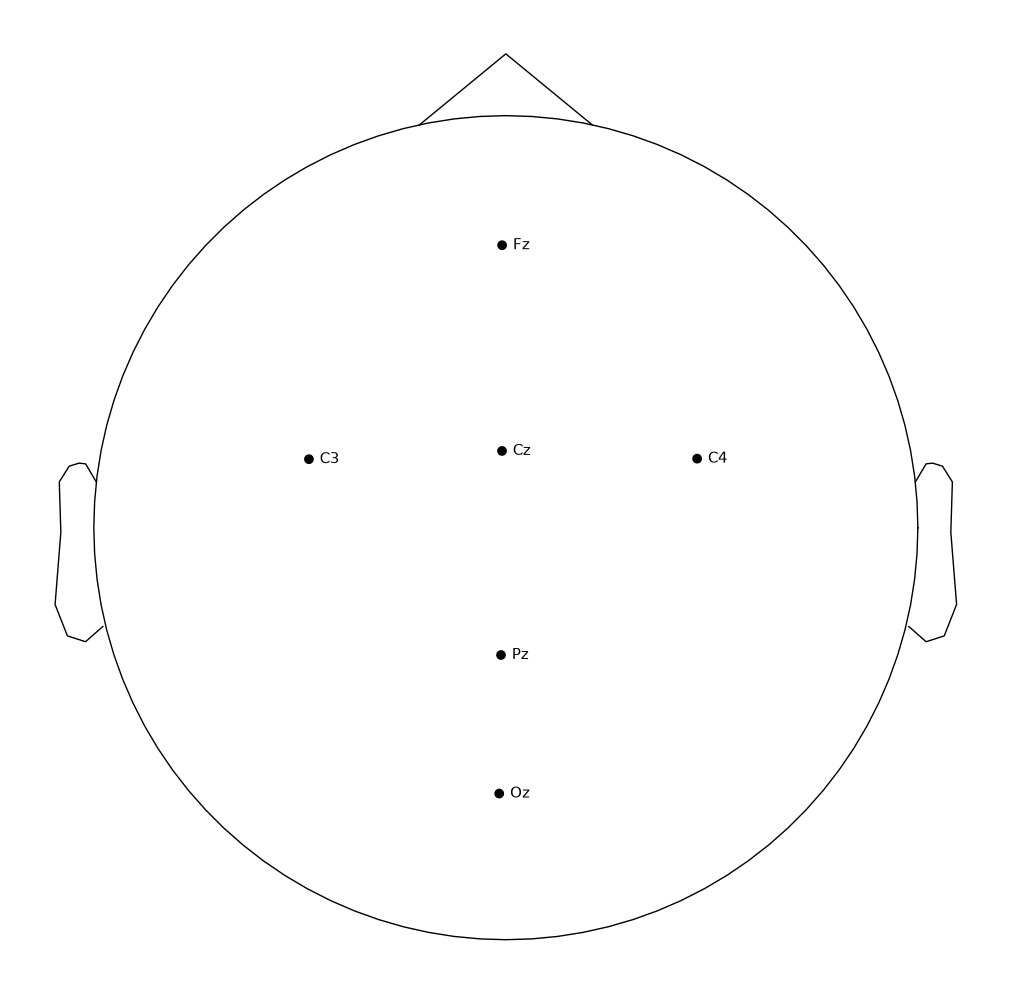

In [73]:
montage = mne.channels.make_standard_montage('colin27_1020')
raw_geo = raw.set_montage(montage)
raw_geo.plot_sensors(show_names=True, show=False)
plt.show()


- `raw.get_montage()` - pozwala dowiedzieć sie jaki montaż został przypisany do pliku raw (nie musi to oznaczać, że ten właśnie montaż został użyty w eksperymencie)
- `montage.ch_names` - lista nazw kanałów
- `montage.get_positions()["ch_pos"]["Cz"]` - pozycje konkrentych kanałów (nie przejmujmy sie tym narazie)

### Eksperyment

Dostajesz kanał nazwany `kanal_1`. Dokumentacja pomiaru mówi, że to Fz.

- **TODO:** najpierw sprawdź komunikat niedopasowania, następnie napraw metadane.
Sprawdź współrzędne i niezmienność próbek. Nie maskuj problemu przez `on_missing='ignore'`.

- Co zrobisz, jeśli nie masz dokumentacji pozwalającej ustalić pozycję?
- Dlaczego mapa czujników nie jest mapą źródeł sygnału?


In [83]:
raw_brakujacykanal = raw.copy().rename_channels({'Fz': 'kanal_1'})
montage = ###? 
raw_brakujacykanal.copy().set_montage(montage)
###
# miejsce na rozwiazanie
###

SyntaxError: invalid syntax (1108444895.py, line 2)

## 5. Adnotacje

`Annotations` to **onset [s] + duration [s] + description**.
- W MNE opisują zdarzenia lub przedziały czasu w ciągłym zapisie Raw. Możesz nimi oznaczyć np. bodziec, fragment z artefaktem, cokolwiek.
- Opisujemy zarówno odcinki (np. ruch przez sekundę), jak i punkty (`duration=0`, np. marker).

Adnotacje przypinamy przez `raw.set_annotations(...)`. **Uwaga: ta metoda zastępuje dotychczasowy zestaw**
- do dopisywania można użyć `raw.annotations.append(...)`.

Opis zaczynający się od `BAD` oznacza zły fragment dla operacji, które respektują takie oznaczenia.

<Annotations | 4 segments: BAD_blink (1), bodziec/lewy (2), bodziec/prawy (1)>
Liczba próbek przed / po: 5000 5000


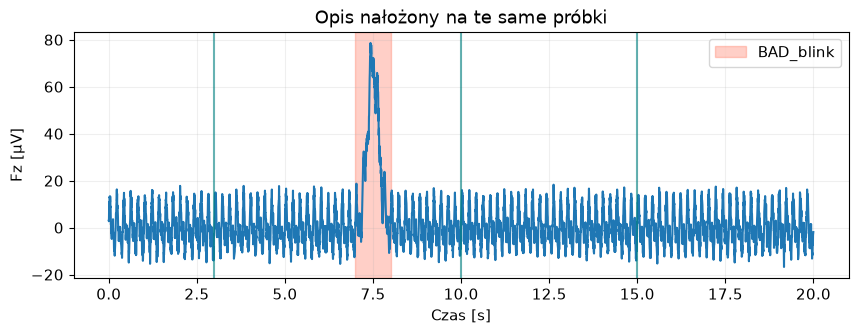

Pobrane próbki po jawnym pominięciu BAD: 4750
Raw nadal ma: 5000


In [84]:
# Czy oznaczenie 1 s jako `BAD_blink` zmieni `n_times`?
raw_ann = raw_geo.copy()
raw_ann.set_annotations(mne.Annotations(
    onset=[3, 7, 10, 15],
    duration=[0, 1, 0, 0],
    description=['bodziec/lewy', 'BAD_blink', 'bodziec/prawy', 'bodziec/lewy']))

print(raw_ann.annotations)

print('Liczba próbek przed / po:', raw_geo.n_times, raw_ann.n_times)

fig, ax = plt.subplots()
ax.plot(raw_ann.times, raw_ann.get_data(picks=['Fz'], units='uV')[0])
for onset, duration, opis in zip(raw_ann.annotations.onset,
                                 raw_ann.annotations.duration,
                                 raw_ann.annotations.description):
    if opis.startswith('BAD'):
        ax.axvspan(onset, onset+duration, color='tomato', alpha=.3, label=opis)
    else:
        ax.axvline(onset, color='teal', alpha=.6)
ax.set(xlabel='Czas [s]', ylabel='Fz [µV]', title='Opis nałożony na te same próbki')
ax.legend(); plt.show()

bez_bad = raw_ann.get_data(picks=['Fz'], reject_by_annotation='omit')
print('Pobrane próbki po jawnym pominięciu BAD:', bez_bad.shape[1])
print('Raw nadal ma:', raw_ann.n_times)


### Eksperyment

Na kopii dopisz odcinek 12–13,5 s jako `BAD_ruch`.
Porównaj długość `Raw` i długość tablicy pobranej z `reject_by_annotation='omit'`.
Następnie zastąp w swoim eksperymencie opis przez `ruch` i powtórz pobranie.
Ten dodatkowy odcinek będzie umownym oznaczeniem do ćwiczenia, nie wykrytym artefaktem.

**Zastanów się:** - Co zmienił prefiks BAD?


In [ ]:
raw_moje_ann = raw_ann.copy()
# Miejsce na rozwiązanie

<Annotations | 5 segments: BAD_blink (1), bodziec/lewy (2), bodziec/prawy ...>
Raw: 5000 | pobrana tablica: 4750


## 6. Anatomia prawdziwego zapisu EEG

Wykorzystamy **S001R03.edf**: osoba 1, rejestracja 3 z publicznego zbioru
[PhysioNet EEG Motor Movement/Imagery](https://physionet.org/content/eegmmidb/1.0.0/).

W tej rejestracji uczestnik wykonuje ruchy lewej lub prawej pięści:
`T0` oznacza odpoczynek, `T1` lewą pięść, `T2` prawą pięść.
Znaczenie T1/T2 zależy od numeru rejestracji — tych opisów nie przenosimy automatycznie na inne pliki.

### Pobranie — wybierz jeden sposób

**A. Przez przeglądarkę**

1. [Pobierz pojedynczy plik S001R03.edf](https://physionet.org/files/eegmmidb/1.0.0/S001/S001R03.edf).
2. Obok notebooka utwórz folder `dane` i zapisz w nim plik pod nazwą `S001R03.edf`.
3. Uruchom poniższą komórkę. Wyświetli pełną ścieżkę, w której szuka pliku.
   Jeśli plik leży gdzie indziej, zmień `plik_edf` na jego ścieżkę, np. `Path('/pełna/ścieżka/S001R03.edf')`.

**B. Bezpośrednio z notebooka**

W poniższej komórce ustaw `POBIERZ_JESLI_BRAK = True` i uruchom ją.
Pobierze wyłącznie ten jeden plik. Jeśli plik już istnieje, nie pobierze go ponownie.


In [86]:
# Pobieranie
from urllib.request import urlopen

URL_EDF = 'https://physionet.org/files/eegmmidb/1.0.0/S001/S001R03.edf'
plik_edf = Path('dane') / 'S001R03.edf'
POBIERZ_JESLI_BRAK = True

print('Szukam pliku:', plik_edf.resolve())
if not plik_edf.exists() and POBIERZ_JESLI_BRAK:
    plik_edf.parent.mkdir(parents=True, exist_ok=True)
    # Zapis dopiero po odebraniu całego pliku; przerwane pobieranie nie tworzy EDF.
    with urlopen(URL_EDF, timeout=60) as odpowiedz:
        zawartosc = odpowiedz.read()
    if zawartosc[:8].strip() != b'0':
        raise ValueError('Pobrana zawartość nie wygląda jak EDF. Użyj linku w przeglądarce.')
    plik_edf.write_bytes(zawartosc)

if not plik_edf.is_file():
    raise FileNotFoundError(
        'Pobierz S001R03.edf do folderu dane lub ustaw POBIERZ_JESLI_BRAK=True, '
        'a następnie ponownie uruchom tę komórkę.')
print('Plik gotowy, rozmiar:', round(plik_edf.stat().st_size/1e6, 2), 'MB')


Szukam pliku: /Users/bejson/University/Dydaktyka/ADNeuroPy/dane/S001R03.edf
Plik gotowy, rozmiar: 2.6 MB


### 6.1. `Raw` i `Info`: co zawiera plik?

Odczytaj obiekt i jego metadane.

Parametr `preload=True` ładuje próbki do pamięci. Dzięki temu dane są gotowe do operacji zmieniających sygnał, takich jak filtrowanie, zmiana referencji czy interpolacja kanałów.
Przy `preload=False` MNE wczytuje informacje o zapisie, a próbki sygnału odczytuje z pliku w miarę potrzeby, np. podczas przeglądania lub użycia get_data(). To oszczędza RAM przy dużych plikach.

Możemy sprawdzić w jakich jednostkach zapisano dane przy pomocy `raw_real._orig_units`


In [90]:
raw_real = mne.io.read_raw_edf(plik_edf, preload=True, verbose=False)

In [ ]:
raw_real.info

<RawEDF | S001R03.edf, 64 x 20000 (125.0 s), ~9.8 MiB, data loaded>

In [87]:
raw_real = mne.io.read_raw_edf(plik_edf, preload=True, verbose=False)
print(raw_real)
print(raw_real.info)
print('Kształt kanały × próbki:', raw_real.get_data().shape)
print('sfreq [Hz]:', raw_real.info['sfreq'])
print('Pokrycie zapisu [s]:', raw_real.n_times/raw_real.info['sfreq'])
print('Czas ostatniej próbki [s]:', raw_real.times[-1])
print('first_samp:', raw_real.first_samp)
print('Data z nagłówka:', raw_real.info['meas_date'])
print('Złe kanały zapisane w metadanych:', raw_real.info['bads'])


<RawEDF | S001R03.edf, 64 x 20000 (125.0 s), ~9.8 MiB, data loaded>
<Info | 8 non-empty values
 bads: []
 ch_names: Fc5., Fc3., Fc1., Fcz., Fc2., Fc4., Fc6., C5.., C3.., C1.., ...
 chs: 64 EEG
 custom_ref_applied: False
 highpass: 0.0 Hz
 lowpass: 80.0 Hz
 meas_date: 2009-08-12 16:15:00 UTC
 nchan: 64
 projs: []
 sfreq: 160.0 Hz
 subject_info: <subject_info | his_id: X, sex: 0, last_name: X>
>
Kształt kanały × próbki: (64, 20000)
sfreq [Hz]: 160.0
Pokrycie zapisu [s]: 125.0
Czas ostatniej próbki [s]: 124.99375
first_samp: 0
Data z nagłówka: 2009-08-12 16:15:00+00:00
Złe kanały zapisane w metadanych: []


### 6.2. Nazwy i typy kanałów

Czy plik z prawdziwym EEG musi mieć osobne kanały EOG, ECG i stim?
Obejrzyj wszystkie nazwy i typy. Nazwy w tym zbiorze mają specyficzny zapis;

In [93]:
nazwy_przed = raw_real.ch_names.copy()
probki_przed = raw_real.get_data(start=0, stop=10).copy()
mne.datasets.eegbci.standardize(raw_real)
for stara, nowa, typ in zip(nazwy_przed, raw_real.ch_names, raw_real.get_channel_types()):
    print(f'{stara:8s} → {nowa:5s} | {typ}')
print('Liczby bez zmian:', np.array_equal(probki_przed, raw_real.get_data(start=0, stop=10)))
print('Liczebności typów:', {t: raw_real.get_channel_types().count(t)
                           for t in sorted(set(raw_real.get_channel_types()))})
print('Czy jest stim?', 'stim' in raw_real.get_channel_types())


FC5      → FC5   | eeg
FC3      → FC3   | eeg
FC1      → FC1   | eeg
FCz      → FCz   | eeg
FC2      → FC2   | eeg
FC4      → FC4   | eeg
FC6      → FC6   | eeg
C5       → C5    | eeg
C3       → C3    | eeg
C1       → C1    | eeg
Cz       → Cz    | eeg
C2       → C2    | eeg
C4       → C4    | eeg
C6       → C6    | eeg
CP5      → CP5   | eeg
CP3      → CP3   | eeg
CP1      → CP1   | eeg
CPz      → CPz   | eeg
CP2      → CP2   | eeg
CP4      → CP4   | eeg
CP6      → CP6   | eeg
Fp1      → Fp1   | eeg
Fpz      → Fpz   | eeg
Fp2      → Fp2   | eeg
AF7      → AF7   | eeg
AF3      → AF3   | eeg
AFz      → AFz   | eeg
AF4      → AF4   | eeg
AF8      → AF8   | eeg
F7       → F7    | eeg
F5       → F5    | eeg
F3       → F3    | eeg
F1       → F1    | eeg
Fz       → Fz    | eeg
F2       → F2    | eeg
F4       → F4    | eeg
F6       → F6    | eeg
F8       → F8    | eeg
FT7      → FT7   | eeg
FT8      → FT8   | eeg
T7       → T7    | eeg
T8       → T8    | eeg
T9       → T9    | eeg
T10      → 

### 6.3. Montage: dodaj geometrię
Czy samne nazwy elektrtod wystarczą do narysowania ich pozycji?
Sprawdź montage po imporcie, a następnie przypisz wzorcowe pozycje.
Geometria `colin27_1005` obejmuje potrzebne nazwy elektrod; jest szablonem, nie indywidualnym pomiarem głowy tej osoby.
Zapis EDF nie zawiera tu takiego pomiaru.


Montage po imporcie: <DigMontage | 0 extras (headshape), 0 HPIs, 3 fiducials, 64 channels>
Układ współrzędnych: head
Liczba pozycji: 64
C3 [m]: [-0.06714873  0.02335823  0.10451068]
Cz [m]: [-0.00137414  0.02761709  0.14019949]
C4 [m]: [0.06532887 0.0235731  0.10369243]


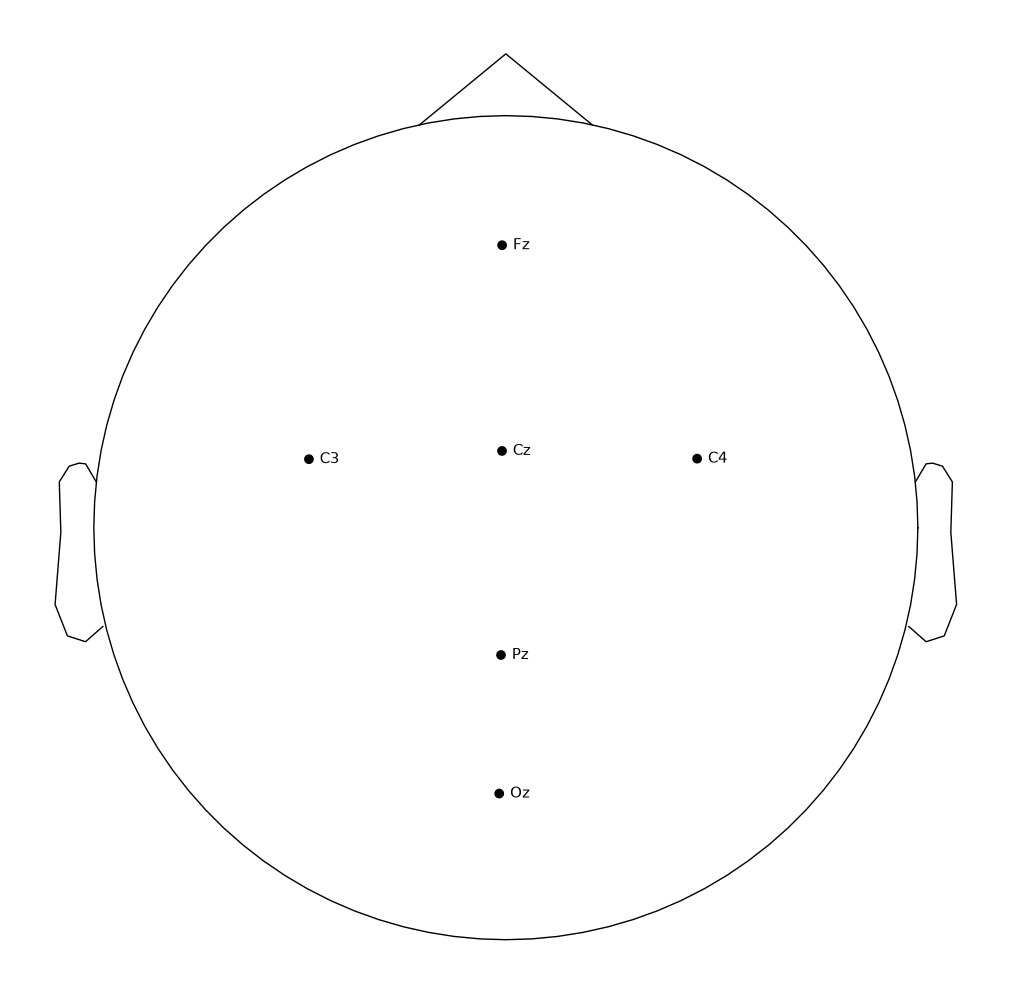

In [94]:
print('Montage po imporcie:', raw_real.get_montage())
raw_real.set_montage(mne.channels.make_standard_montage('colin27_1020'))
real_positions = raw_real.get_montage().get_positions()
print('Układ współrzędnych:', real_positions['coord_frame'])
print('Liczba pozycji:', len(real_positions['ch_pos']))
for ch in ['C3', 'Cz', 'C4']:
    print(ch, '[m]:', real_positions['ch_pos'][ch])
raw_real.copy().pick(['C3', 'Cz', 'C4', 'Fz', 'Pz', 'Oz']).plot_sensors(
    show_names=True, show=False)
plt.show()


### 6.4. Annotations: co i kiedy robiono?

Odczytaj początki, długości i opisy. Czas w tabeli to sekundy od początku zapisu.
Brak adnotacji `BAD` nie dowodzi, że EEG nie ma artefaktów — oznacza tylko brak takich etykiet.


In [96]:
print(raw_real.annotations)
print('orig_time:', raw_real.annotations.orig_time)
print('początek [s] | długość [s] | opis')
for onset, duration, desc in zip(raw_real.annotations.onset[:12],
                                raw_real.annotations.duration[:12],
                                raw_real.annotations.description[:12]):
    print(f'{onset-raw_real.first_time:12.3f} | {duration:11.3f} | {desc}')
print('Unikalne opisy:', np.unique(raw_real.annotations.description))


<Annotations | 30 segments: T0 (15), T1 (8), T2 (7)>
orig_time: 2009-08-12 16:15:00+00:00
początek [s] | długość [s] | opis
       0.000 |       4.200 | T0
       4.200 |       4.100 | T2
       8.300 |       4.200 | T0
      12.500 |       4.100 | T1
      16.600 |       4.200 | T0
      20.800 |       4.100 | T1
      24.900 |       4.200 | T0
      29.100 |       4.100 | T2
      33.200 |       4.200 | T0
      37.400 |       4.100 | T2
      41.500 |       4.200 | T0
      45.700 |       4.100 | T1
Unikalne opisy: ['T0' 'T1' 'T2']


### 6.5. Prawdziwe napięcia i etykiety na jednej osi czasu

Obejrzyj 20 sekund trzech kanałów.

EEG pokazujemy w µV, a poniżej oznaczamy odcinki odpoczynku i ruchu. Kolor oznacza zadanie, nie automatycznie wykryty stan mózgu.


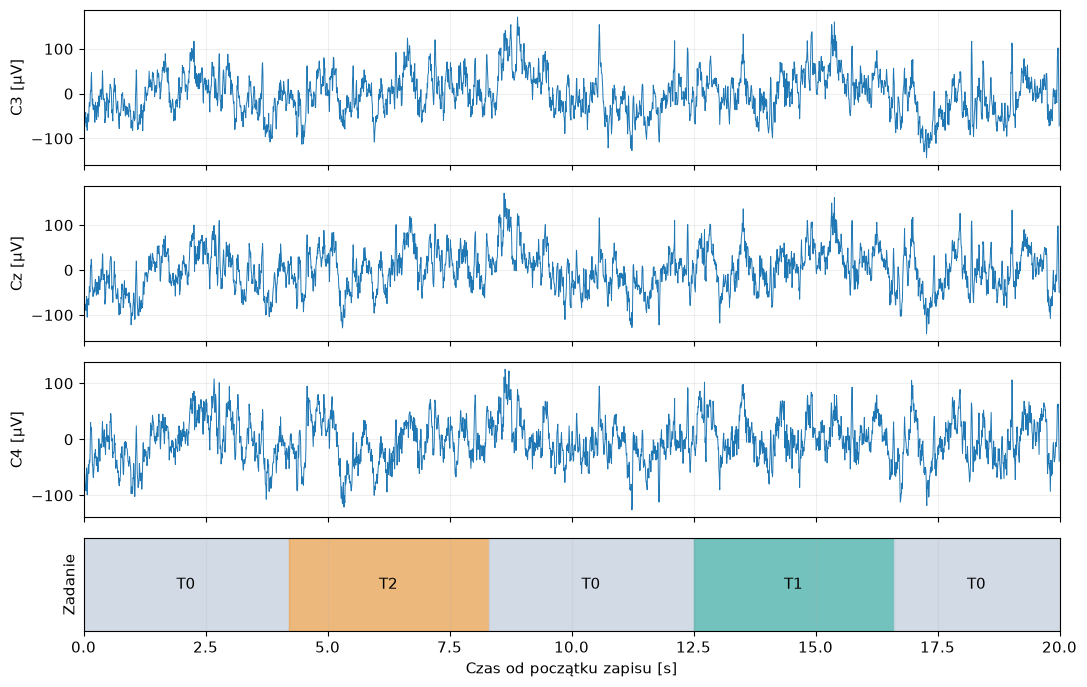

{'T0': 'odpoczynek', 'T1': 'lewa pięść', 'T2': 'prawa pięść'}


In [ ]:
start_s, stop_s = 0.0, 20.0
start_idx, stop_idx = raw_real.time_as_index([start_s, stop_s])
kanaly_real = ['C3', 'Cz', 'C4']
sygnal_uv = raw_real.get_data(picks=kanaly_real, start=start_idx, stop=stop_idx, units='uV')
fig, axes = plt.subplots(4, 1, sharex=True, figsize=(11, 7),
                         gridspec_kw={'height_ratios': [1, 1, 1, .6]})
for ax, ch, y in zip(axes[:3], kanaly_real, sygnal_uv):
    ax.plot(raw_real.times[start_idx:stop_idx], y, linewidth=.7)
    ax.set_ylabel(f'{ch} [µV]')
kolory = {'T0': '#cbd5e1', 'T1': '#5cb8b2', 'T2': '#e9ac65'}
opisy = {'T0': 'odpoczynek', 'T1': 'lewa pięść', 'T2': 'prawa pięść'}
for onset, dur, desc in zip(raw_real.annotations.onset, raw_real.annotations.duration,
                            raw_real.annotations.description):
    t0 = onset - raw_real.first_time
    a, b = max(start_s, t0), min(stop_s, t0+dur)
    if b > a and desc in kolory:
        axes[3].axvspan(a, b, color=kolory[desc], alpha=.85)
        axes[3].text((a+b)/2, .5, desc, ha='center', va='center')
axes[3].set(yticks=[], ylabel='Zadanie', xlabel='Czas od początku zapisu [s]',
            xlim=(start_s, stop_s), ylim=(0, 1))
plt.tight_layout(); plt.show()
print(opisy)


### Twój audyt rzeczywistych danych

'https://physionet.org/files/eegmmidb/1.0.0/S001/S001R04.edf'

**TODO:** Pobierz dane, wybierz kanał i  przedział czasu, a następnie przygotuj krótką kartę zapisu.

- Ile jest kanałów i próbek? Jaki jest czas trwania i częstotliwość próbkowania?
- Jakie typy kanałów występują? Jakich znanych Ci typów nie ma?
- Które informacje odczytano z pliku, a które dołączyliśmy sami?
- Znajdź pierwszy marker T2. Podaj numer próbki i czas od początku zapisu.


%% Miejsce na rozwiązanie %%

## 9. Mini-zadanie: Zasymuluj swój eksperyment

Przygotuj symulację sygnału EEG, który otrzyma inna osoba. Jej zadaniem będzie wczytanie pliku i ustalenie, co zostało w nim zapisane — bez zaglądania do Twojego kodu.

Dane startowe: 
- 3-6 kanałów,
- 10-60 sekund,
- 200-500 Hz
- Własne bodźce (conajmniej 3 typy w formie adnotacji)
- przypisany montaż
- jeden fragment oznaczony jako zły, np. BAD_ruch.

Zapisz plik do formatu _raw.fif i udostępnij znajomemu  

`raw.save("eksperyment_raw.fif", overwrite=True)`


In [ ]:
### Rozwiązanie